# Uso de IA en estudiantes y profesionales

El dataset recoge información sobre el uso de herramientas de inteligencia artificial por estudiantes y profesionales. Contiene 300 registros y 19 columnas con datos sobre el perfil de los usuarios, las herramientas utilizadas, los fines de uso, las horas dedicadas a la IA y medidas de productividad, satisfacción y ahorro de tiempo. Nos permite comparar ambos grupos y explorar las relaciones entre estas variables.

En esta práctica vamos a representar el mismo dataset con Matplotlib y Seaborn
para comparar cómo se prepara y se personaliza cada gráfico.

Los datos proceden del dataset [AI Usage and Impact on Students & Professionals](https://www.kaggle.com/datasets/eishatuzzuhra/ai-usage-and-impact-on-students-and-professionals)
de Eisha Tuz Zuhra (Kaggle), publicado con licencia CC0 (dominio público).

# 1. Preparar el entorno

Utilizamos las bibliotecas de `requirements-notebook.txt`. Antes de ejecutar el cuaderno,
deben estar instaladas en el entorno de Python seleccionado.
El CSV está en la carpeta `data`, así que no hace falta descargarlo.

In [1]:
import pandas as pd
from pathlib import Path
from IPython.display import display

## 2. Cargar CSV con pandas

In [2]:
# Ruta del CSV, relativa a la carpeta del proyecto (donde está este cuaderno)
csv_path = Path("data/AI_Usage_and_Impact_on_Students_and_Professionals.csv")

# Cargar el dataset
df = pd.read_csv(csv_path)

# Mostrar las primeras filas
display(df.head())

# Comprobar las dimensiones del dataset
print("Dimensiones:", df.shape)

# Mostrar los nombres de las columnas
print("\nColumnas:")
print(df.columns.tolist())

# Comprobar cuántos valores faltan en cada columna
print("\nValores ausentes:")
print(df.isnull().sum())

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2 hrs,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4 hrs,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,Chat GPT,Coding,1 hrs,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


Dimensiones: (300, 19)

Columnas:
['User_ID', 'Age', 'Gender', 'Country', 'User_Type', 'Education_Level', 'Profession', 'Monthly_Income', 'AI_Tool', 'AI_Purpose', 'AI_Usage_Hours_Per_Day', 'Tasks_Performed', 'Monthly_AI_Cost', 'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day', 'Would_Recommend']

Valores ausentes:
User_ID                         0
Age                            23
Gender                         10
Country                        10
User_Type                       0
Education_Level                13
Profession                     15
Monthly_Income                 10
AI_Tool                        11
AI_Purpose                     13
AI_Usage_Hours_Per_Day          7
Tasks_Performed                18
Monthly_AI_Cost                12
Productivity_Score             16
Accuracy_Rating                15
Satisfaction_Score              7
Time_Saved_Hours_Per_Week      10
Work_or_Study_Hours_Per_Day     9


## 3. Preparar los datos

Eliminamos las filas repetidas, convertimos las horas a números y unificamos los
nombres de las herramientas. Conservamos las ausencias y los valores extremos;
cada gráfico seleccionará los registros con la información que necesita.

In [3]:
# Eliminar únicamente los registros completamente repetidos
filas_originales = len(df)
df = df.drop_duplicates().copy()


# Convertir horas escritas como "2 hrs" a valores numéricos
columnas_horas = [
    "AI_Usage_Hours_Per_Day",
    "Time_Saved_Hours_Per_Week",
    "Work_or_Study_Hours_Per_Day"
]
for columna in columnas_horas:
    df[columna] = pd.to_numeric(
        df[columna].str.replace("hrs", "", regex=False).str.strip(),
        errors="coerce"
    )

# Unificar los nombres de herramientas que aparecen escritos de varias formas
df["AI_Tool"] = df["AI_Tool"].str.strip().str.lower().replace({
    "chatgpt": "ChatGPT", "chat gpt": "ChatGPT",
    "google gemini": "Google Gemini", "gemini": "Google Gemini",
    "microsoft copilot": "Microsoft Copilot", "copilot": "Microsoft Copilot",
    "claude": "Claude", "perplexity ai": "Perplexity AI",
    "grammarly": "Grammarly", "meta ai": "Meta AI", "deepseek": "DeepSeek"
})


# Comprobar el resultado de la limpieza
print("Duplicados eliminados:", filas_originales - len(df))
print("Registros disponibles:", len(df))
display(df.head())

Duplicados eliminados: 12
Registros disponibles: 288


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421,ChatGPT,Office Work,2.0,Data analysis using AI-powered analytics tools...,NaN,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0,9.9,3.0,9.0,11.4,8.4,Yes
2,U0152,17,Male,Canada,Student,NaN,Computer Science Student,402,ChatGPT,Coding,1.0,NaN,20,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35,FEMALE,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438,Perplexity AI,NaN,4.1,Using AI to generate study summaries for exam ...,0,4.7,4.0,7.0,9.2,6.2,Yes


# Gráfico 1. Diagrama de barras

## Preparación de los datos

Vamos a comparar las cinco herramientas de IA más frecuentes entre estudiantes
y profesionales. Contamos los registros de cada grupo para cada herramienta.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Seleccionar los dos tipos de usuario que vamos a comparar
tipos = ["Student", "Professional"]

# Traducir los nombres de los grupos al español
etiquetas = {"Student": "Estudiantes", "Professional": "Profesionales"}

# Mantener los mismos colores en las dos bibliotecas
colores = {"Student": "#0891b2", "Professional": "#9333ea"}

# Seleccionar las cinco herramientas con más registros
top5 = df["AI_Tool"].value_counts().head(5).index

# Contar los registros de cada herramienta por tipo de usuario
tabla = pd.crosstab(df["AI_Tool"], df["User_Type"]).loc[top5, tipos]
display(tabla.rename(columns=etiquetas))

User_Type,Estudiantes,Profesionales
AI_Tool,,
ChatGPT,62,57
Google Gemini,20,19
Microsoft Copilot,20,13
Claude,19,12
Perplexity AI,10,13


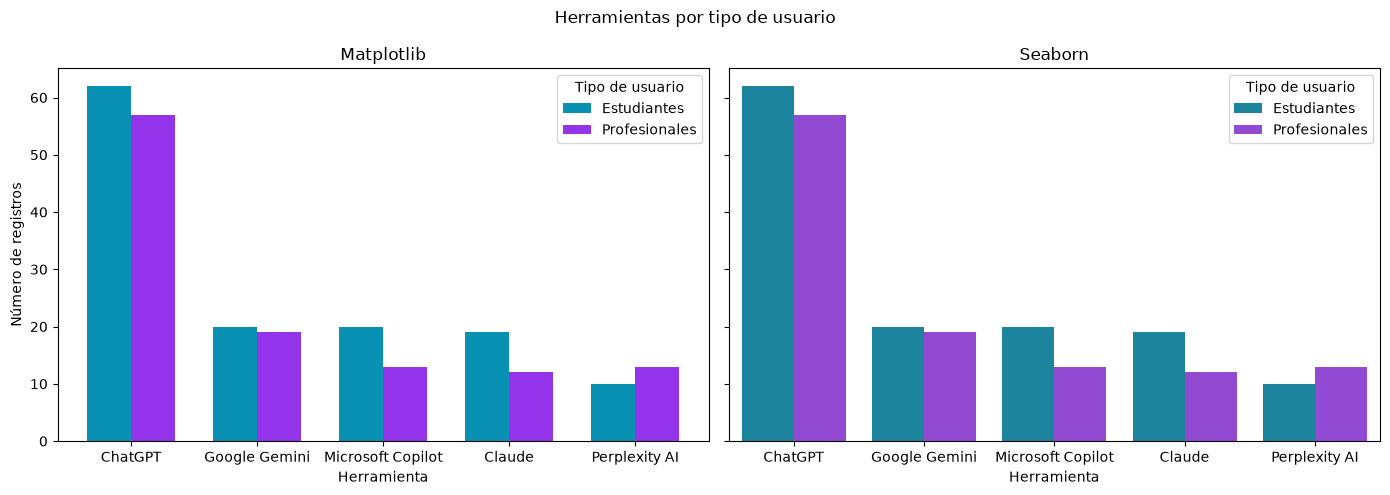

In [5]:
# Comparar Matplotlib (izquierda) y Seaborn (derecha) con el mismo eje vertical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Matplotlib: calculamos a mano la posición de cada barra del grupo
x = np.arange(len(tabla))
for i, tipo in enumerate(tipos):
    ax1.bar(x + (i - 0.5) * 0.35, tabla[tipo], width=0.35,
            label=etiquetas[tipo], color=colores[tipo])
ax1.set_xticks(x, tabla.index)
ax1.set_title("Matplotlib")
ax1.set_xlabel("Herramienta")
ax1.set_ylabel("Número de registros")
ax1.legend(title="Tipo de usuario")

# Seaborn: convertimos los recuentos a formato largo y usamos hue
largo = tabla.rename_axis('Herramienta').reset_index().melt(
    id_vars='Herramienta', var_name='Tipo', value_name='Registros')
sns.barplot(data=largo, x='Herramienta', y='Registros', hue='Tipo',
            hue_order=tipos, palette=colores, errorbar=None, ax=ax2)
ax2.set_title("Seaborn")
ax2.set_xlabel("Herramienta")
ax2.set_ylabel("Número de registros")
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles, [etiquetas[v] for v in labels], title='Tipo de usuario')

fig.suptitle("Herramientas por tipo de usuario")
fig.tight_layout()
plt.show()
plt.close(fig)

# Gráfico 2. Líneas múltiples

## Preparación de los datos

Agrupamos el uso diario de IA en tramos y calculamos la productividad media de
cada grupo. Las líneas comparan intervalos de horas, no una evolución temporal.

In [6]:
# Definir los intervalos de horas diarias de uso de IA
tramos_uso = ["0–2", ">2–4", ">4–6", ">6–24"]


# Agrupar las horas diarias de IA en tramos ordenados
datos_lineas = df.copy()
datos_lineas['Tramo_IA'] = pd.cut(
    datos_lineas['AI_Usage_Hours_Per_Day'], [0, 2, 4, 6, 24],
    labels=tramos_uso, include_lowest=True
)

# Calcular la productividad media por tramo y tipo de usuario
medias = datos_lineas.pivot_table(
    index='Tramo_IA', columns='User_Type', values='Productivity_Score',
    aggfunc='mean', observed=True
).reindex(tramos_uso)
display(medias.rename(columns=etiquetas))

User_Type,Profesionales,Estudiantes
Tramo_IA,,
0–2,4.104615,3.891304
>2–4,5.737500,5.509091
>4–6,7.157692,6.784211
>6–24,7.033333,8.052941


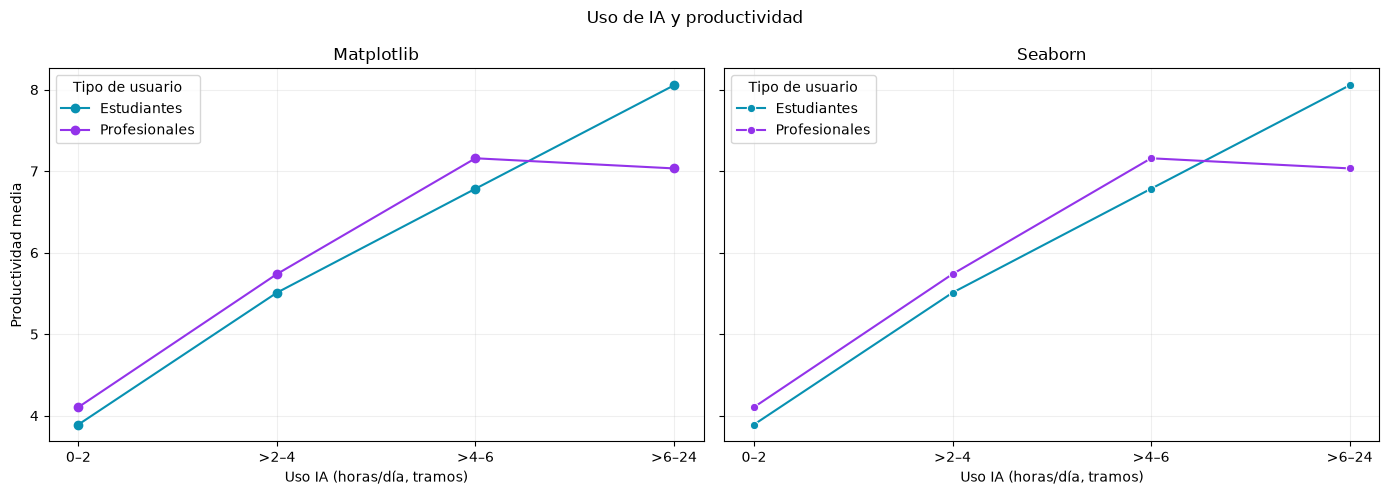

In [7]:
# Comparar Matplotlib (izquierda) y Seaborn (derecha) con el mismo eje vertical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Matplotlib: una línea por cada tipo de usuario
for tipo in tipos:
    ax1.plot(tramos_uso, medias[tipo], marker='o', color=colores[tipo], label=etiquetas[tipo])
ax1.set_title("Matplotlib")
ax1.set_xlabel("Uso IA (horas/día, tramos)")
ax1.set_ylabel("Productividad media")
ax1.legend(title="Tipo de usuario")
ax1.grid(alpha=0.2)

# Seaborn: convertimos las medias a formato largo y usamos hue
largo = medias.rename_axis('Tramo').reset_index().melt(
    id_vars='Tramo', var_name='Tipo', value_name='Productividad')
sns.lineplot(data=largo, x='Tramo', y='Productividad', hue='Tipo', hue_order=tipos,
             palette=colores, marker='o', errorbar=None, sort=False, ax=ax2)
ax2.set_title("Seaborn")
ax2.set_xlabel("Uso IA (horas/día, tramos)")
ax2.set_ylabel("Productividad media")
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles, [etiquetas[v] for v in labels], title='Tipo de usuario')
ax2.grid(alpha=0.2)

fig.suptitle("Uso de IA y productividad")
fig.tight_layout()
plt.show()
plt.close(fig)

# Gráfico 3. Gráfico de burbujas

## Preparar los datos

Relacionamos el uso diario de IA con el ahorro semanal. El color representa el tipo
de usuario y el área de la burbuja, la satisfacción. No recortamos valores extremos.

El uso diario más alto es un valor extremo de 23 horas. Lo conservamos porque no
podemos comprobar si es un error, pero estira el eje horizontal del gráfico.

In [8]:
# Seleccionar los registros con información suficiente para las burbujas
datos_burbujas = df.dropna(subset=['AI_Usage_Hours_Per_Day', 'Time_Saved_Hours_Per_Week', 'Satisfaction_Score'])
print(f'Registros completos: {len(datos_burbujas)} de {len(df)}')

# Comprobar los mayores usos diarios, entre ellos el valor extremo que conservamos
print('Mayores usos diarios de IA (horas):', datos_burbujas['AI_Usage_Hours_Per_Day'].nlargest(3).tolist())

Registros completos: 264 de 288
Mayores usos diarios de IA (horas): [23.0, 9.9, 9.8]


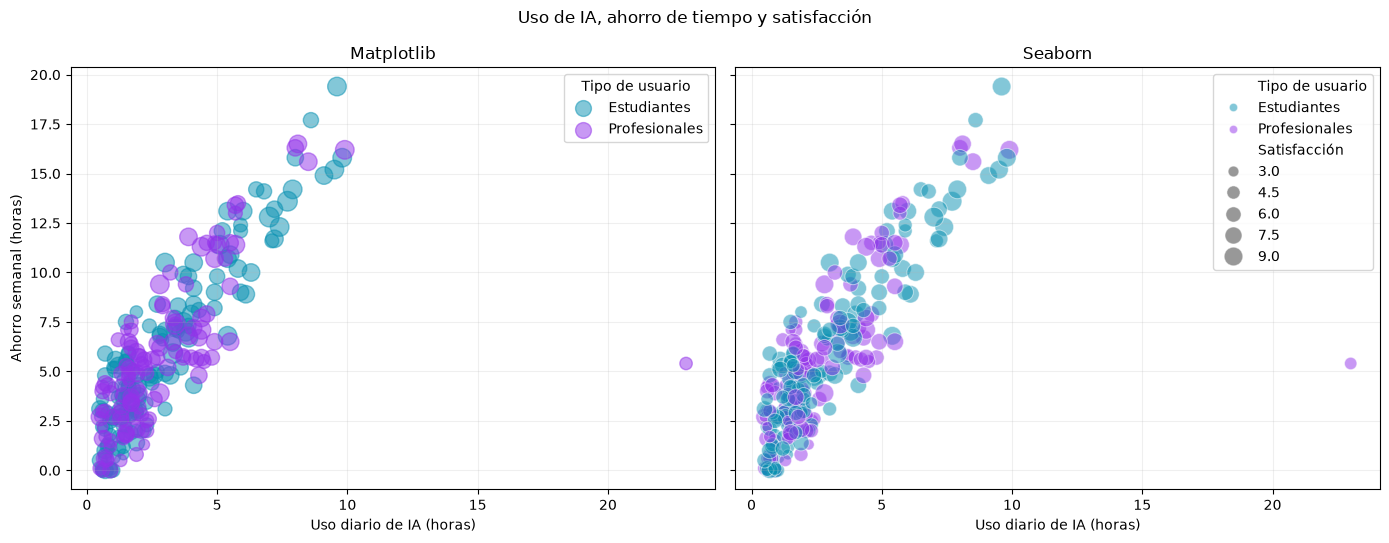

In [9]:
# Comparar Matplotlib (izquierda) y Seaborn (derecha) con los mismos ejes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)

# Matplotlib: una serie de burbujas por tipo de usuario
for tipo in tipos:
    grupo = datos_burbujas[datos_burbujas['User_Type'] == tipo]
    ax1.scatter(grupo['AI_Usage_Hours_Per_Day'], grupo['Time_Saved_Hours_Per_Week'],
                s=grupo['Satisfaction_Score'] * 20, alpha=0.5,
                color=colores[tipo], label=etiquetas[tipo])
ax1.set_title("Matplotlib")
ax1.set_xlabel('Uso diario de IA (horas)')
ax1.set_ylabel('Ahorro semanal (horas)')
ax1.legend(title='Tipo de usuario')
ax1.grid(alpha=0.2)

# Seaborn: hue para el color y size para la satisfacción
sns.scatterplot(data=datos_burbujas, x='AI_Usage_Hours_Per_Day', y='Time_Saved_Hours_Per_Week',
                hue='User_Type', hue_order=tipos, palette=colores, size='Satisfaction_Score',
                size_norm=(0, 10), sizes=(0, 200), alpha=0.5, ax=ax2)
# La leyenda de Seaborn usa los nombres de las columnas: la traducimos al español
traduccion = {**etiquetas, 'User_Type': 'Tipo de usuario', 'Satisfaction_Score': 'Satisfacción'}
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(handles, [traduccion.get(v, v) for v in labels])
ax2.set_title("Seaborn")
ax2.set_xlabel('Uso diario de IA (horas)')
ax2.set_ylabel('Ahorro semanal (horas)')
ax2.grid(alpha=0.2)

fig.suptitle("Uso de IA, ahorro de tiempo y satisfacción")
fig.tight_layout()
plt.show()
plt.close(fig)

# Gráfico 4. Distribución de puntuaciones

## Preparar los datos

Seleccionamos las puntuaciones de productividad disponibles y representamos su
distribución con un histograma y una curva de densidad KDE.

In [10]:
# Seleccionar las puntuaciones válidas y comprobar cuántas vamos a representar
puntuaciones = df.Productivity_Score.dropna()
print(f'Puntuaciones disponibles: {len(puntuaciones)}; ausentes: {df.Productivity_Score.isna().sum()}')
display(puntuaciones.describe())
bordes = np.histogram_bin_edges(puntuaciones, bins=15)

Puntuaciones disponibles: 274; ausentes: 14


count    274.000000
mean       5.235036
std        1.821789
min        1.600000
25%        3.900000
50%        5.000000
75%        6.500000
max       10.000000
Name: Productivity_Score, dtype: float64

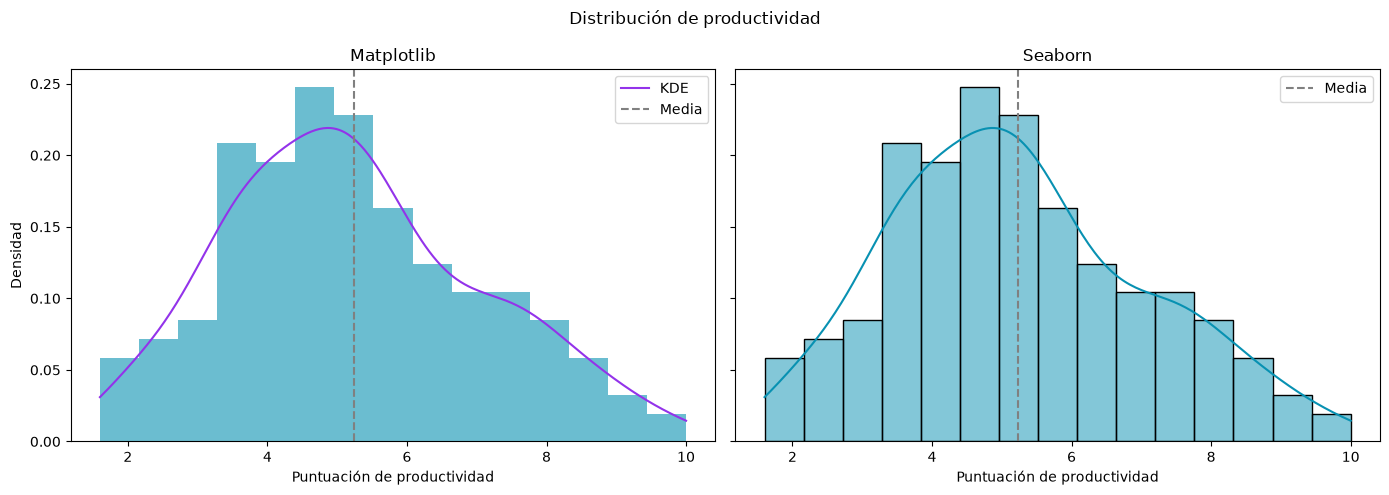

In [11]:
from scipy.stats import gaussian_kde

# Comparar Matplotlib (izquierda) y Seaborn (derecha) con los mismos ejes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)

# Matplotlib: histograma como densidad y KDE calculada con SciPy
ax1.hist(puntuaciones, bins=bordes, density=True, color='#0891b2', alpha=0.6)
kde = gaussian_kde(puntuaciones)
x = np.linspace(puntuaciones.min(), puntuaciones.max(), 300)
ax1.plot(x, kde(x), color='#9333ea', label='KDE')
ax1.axvline(puntuaciones.mean(), linestyle='--', color='gray', label='Media')
ax1.set_title("Matplotlib")
ax1.set_xlabel("Puntuación de productividad")
ax1.set_ylabel("Densidad")
ax1.legend()

# Seaborn: el histograma y la KDE se piden con una sola llamada (kde=True)
sns.histplot(puntuaciones, bins=bordes, stat='density', kde=True,
             kde_kws={'cut': 0}, color='#0891b2', ax=ax2)
ax2.axvline(puntuaciones.mean(), linestyle='--', color='gray', label='Media')
ax2.set_title("Seaborn")
ax2.set_xlabel("Puntuación de productividad")
ax2.set_ylabel("Densidad")
ax2.legend()

fig.suptitle("Distribución de productividad")
fig.tight_layout()
plt.show()
plt.close(fig)

# Gráfico 5. Gráfico en 3D

## Preparar los datos

Calculamos el ahorro semanal medio por tramos de uso de IA y de jornada. Dejamos
vacías las combinaciones con menos de tres observaciones. Los tramos se dibujan
equidistantes aunque su anchura cambia; la superficie es una representación descriptiva.

In [12]:
# Definir los intervalos de horas de trabajo o estudio
tramos_jornada = ["0–4", ">4–6", ">6–8", ">8–24"]


# Agrupar las horas de IA y la jornada en tramos
datos_3d = df.copy()
datos_3d['Tramo_IA'] = pd.cut(
    datos_3d['AI_Usage_Hours_Per_Day'], [0, 2, 4, 6, 24],
    labels=tramos_uso, include_lowest=True
)
datos_3d['Tramo_jornada'] = pd.cut(
    datos_3d['Work_or_Study_Hours_Per_Day'], [0, 4, 6, 8, 24],
    labels=tramos_jornada, include_lowest=True
)

# Calcular el ahorro medio y el número de observaciones por combinación
z = datos_3d.pivot_table(
    index='Tramo_jornada', columns='Tramo_IA', values='Time_Saved_Hours_Per_Week',
    aggfunc='mean', observed=True
).reindex(index=tramos_jornada, columns=tramos_uso)
recuentos = datos_3d.pivot_table(
    index='Tramo_jornada', columns='Tramo_IA', values='Time_Saved_Hours_Per_Week',
    aggfunc='count', observed=True
).reindex(index=tramos_jornada, columns=tramos_uso)

# Dejar vacías las combinaciones con menos de tres observaciones
z = z.where(recuentos >= 3)
display(z.round(2))
# Crear las matrices de coordenadas para los tres ejes
X, Y = np.meshgrid(np.arange(4), np.arange(4))
Z = z.to_numpy(dtype=float)

# Mostrar las dimensiones de la superficie y las combinaciones que no se representan
print("Dimensiones de la superficie:", Z.shape)
print("Combinaciones sin datos suficientes:", np.isnan(Z).sum())

Tramo_IA,0–2,>2–4,>4–6,>6–24
Tramo_jornada,,,,
0–4,2.66,NaN,NaN,NaN
>4–6,3.06,6.58,8.66,15.71
>6–8,3.23,6.16,10.34,13.24
>8–24,3.25,5.70,9.07,NaN


Dimensiones de la superficie: (4, 4)
Combinaciones sin datos suficientes: 4


## Matplotlib y Seaborn

Mostramos las dos superficies a la vez. Seaborn solo aporta el estilo de la
cuadrícula; la superficie 3D se dibuja con Matplotlib. Usamos la misma escala de
color para poder comparar las alturas.

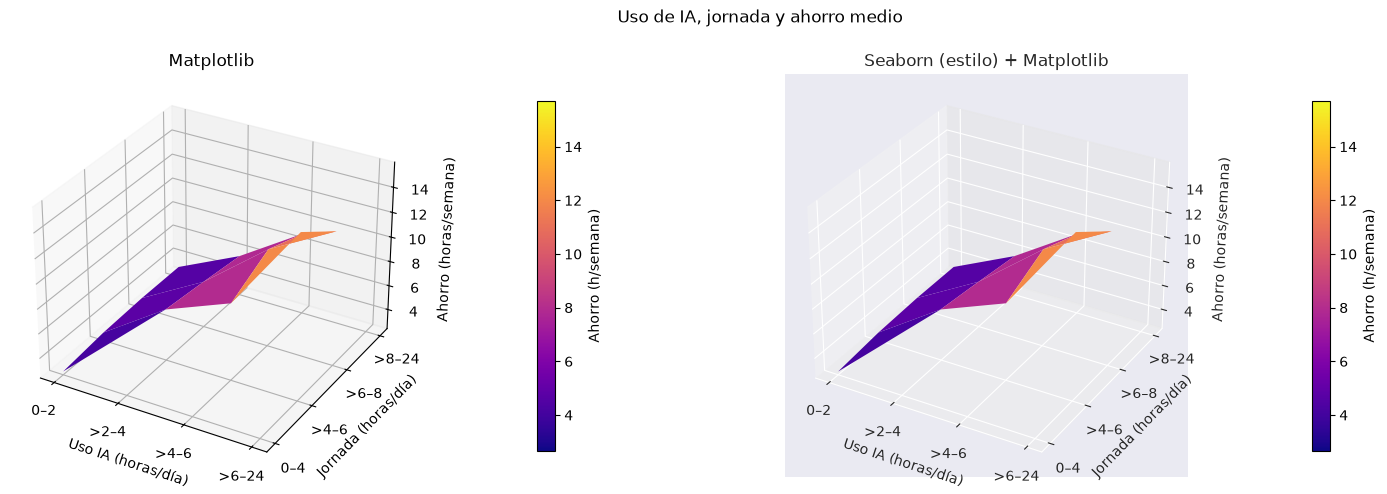

In [13]:
# Comparar las dos superficies con la misma escala de color
fig = plt.figure(figsize=(15, 6.5))
vmin, vmax = np.nanmin(Z), np.nanmax(Z)

# Matplotlib con su estilo por defecto
ax1 = fig.add_subplot(121, projection='3d')
sup1 = ax1.plot_surface(X, Y, Z, cmap='plasma', vmin=vmin, vmax=vmax, edgecolor='none')
ax1.set_title('Matplotlib')

# Seaborn aporta el estilo; la superficie sigue dibujándola Matplotlib.
# El estilo se aplica al crear el eje, por eso lo creamos dentro del bloque with.
with sns.axes_style('darkgrid'):
    ax2 = fig.add_subplot(122, projection='3d')
sup2 = ax2.plot_surface(X, Y, Z, cmap='plasma', vmin=vmin, vmax=vmax, edgecolor='none')
ax2.set_title('Seaborn (estilo) + Matplotlib')

# Etiquetas y barra de color de cada superficie
for ax, sup in ((ax1, sup1), (ax2, sup2)):
    ax.set_xticks(range(4), tramos_uso)
    ax.set_yticks(range(4), tramos_jornada)
    ax.set_xlabel('Uso IA (horas/día)')
    ax.set_ylabel('Jornada (horas/día)')
    ax.set_zlabel('Ahorro (horas/semana)')
    fig.colorbar(sup, ax=ax, shrink=0.55, pad=0.2, label='Ahorro (h/semana)')

fig.suptitle('Uso de IA, jornada y ahorro medio', y=0.92)
fig.subplots_adjust(left=0, right=0.93, bottom=0.02, top=1.0, wspace=0.25)
plt.show()
plt.close(fig)

## Plotly

Esta versión permite girar la superficie y consultar los valores. Es la biblioteca
utilizada para el gráfico interactivo de la aplicación Streamlit.

In [14]:
import plotly.graph_objects as go

# Crear la misma superficie con Plotly para poder girarla
fig = go.Figure(go.Surface(
    x=list(range(4)), y=list(range(4)), z=Z, connectgaps=False,
    colorscale='Plasma', colorbar=dict(title='Ahorro (h)')
))
fig.update_layout(height=650, title='Uso de IA, jornada y ahorro', scene=dict(
    xaxis=dict(title='Uso IA (horas/día)', tickvals=list(range(4)), ticktext=tramos_uso),
    yaxis=dict(title='Jornada (horas/día)', tickvals=list(range(4)), ticktext=tramos_jornada),
    zaxis_title='Ahorro medio (horas/semana)'))
fig.show()

# Conclusiones

## Conclusiones del dataset

Calculamos la herramienta más frecuente, el ahorro medio por grupo y la correlación
entre el uso diario de IA y el ahorro semanal.

In [15]:
# Obtener los resultados principales
herramienta = df['AI_Tool'].value_counts().index[0]
medias_ahorro = df.groupby('User_Type')['Time_Saved_Hours_Per_Week'].mean()
correlacion = df['AI_Usage_Hours_Per_Day'].corr(df['Time_Saved_Hours_Per_Week'])

# Mostrar las conclusiones de la práctica
print(f'La herramienta más frecuente en esta muestra es {herramienta}.')
print(f'Ahorro semanal medio en estudiantes: {medias_ahorro["Student"]:.2f} horas.')
print(f'Ahorro semanal medio en profesionales: {medias_ahorro["Professional"]:.2f} horas.')
print(f'Correlación entre uso diario de IA y ahorro semanal: {correlacion:.2f}.')
print('La asociación observada no demuestra causalidad.')

La herramienta más frecuente en esta muestra es ChatGPT.
Ahorro semanal medio en estudiantes: 6.04 horas.
Ahorro semanal medio en profesionales: 5.55 horas.
Correlación entre uso diario de IA y ahorro semanal: 0.78.
La asociación observada no demuestra causalidad.


## Conclusiones del proyecto

Después de hacer los mismos cinco gráficos con las dos bibliotecas, me quedo con
**Seaborn** para analizar datos. Con menos código consigue lo mismo: en las barras
agrupadas basta con indicar `hue`, sin calcular a mano la posición de cada barra, y en
el histograma `kde=True` dibuja la curva de densidad, que en Matplotlib tuve que
calcular con SciPy. Lo que menos me gustó es que pide los datos en formato largo y que
la leyenda muestra los nombres de las columnas, así que en el gráfico de burbujas tuve
que traducirla.

**Matplotlib** lo usaría cuando necesite controlar cada detalle: colocar las barras,
ajustar los ejes y las leyendas o dibujar la superficie 3D, que Seaborn no hace por sí
solo. Requiere más código, pero permite dejar el gráfico exactamente como quiero.

Para enseñar el resultado, **Streamlit** me ha parecido muy cómodo: reúne los
indicadores, los gráficos y las conclusiones en una aplicación con menú lateral. Para
la superficie 3D interactiva usé **Plotly**, porque permite girarla.

En resumen: Seaborn para analizar, Matplotlib para los ajustes finos y Streamlit para
presentar el trabajo.